In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))

import numpy as np
import pandas as pd
import matplotlib

import matplotlib.pyplot as plt

from config import (
    OHLCV_DIR, ASSET_DAILY_PATH, ASSETS_PATH,
    DATE_COL, TIMESTAMP_COL, CLOSE_COL, ASSET_ID_COL, MARKET_SYMBOL_COL,
)
from helperfunctions import HelperFunctions
helper = HelperFunctions()

print("Imports OK")

Imports OK


In [2]:
# --- Daten laden & vorverarbeiten ---
from helperfunctions import STABLECOIN_SYMBOLS

# Assets-Tabelle: asset_id <-> symbol
assets_df  = pd.read_parquet(ASSETS_PATH)[["asset_id", "symbol"]].drop_duplicates()
id_to_symbol = dict(zip(assets_df["asset_id"], assets_df["symbol"]))
sym_to_id    = dict(zip(assets_df["symbol"], assets_df["asset_id"]))

# Stablecoin asset_ids berechnen, werden aus der Point Cloud ausgeschlossen
excluded_ids: set[int] = set(
    assets_df.loc[assets_df["symbol"].isin(STABLECOIN_SYMBOLS), "asset_id"].tolist()
)
excluded_syms = sorted(assets_df.loc[assets_df["asset_id"].isin(excluded_ids), "symbol"])
print(f"Ausgeschlossene Stablecoins: {excluded_syms}")

ohlcv_files = sorted(OHLCV_DIR.glob("*.parquet"))
print(f"\nOHLCV-Dateien gefunden: {len(ohlcv_files)}")

raw = pd.concat([pd.read_parquet(f) for f in ohlcv_files], ignore_index=True)
raw["base_symbol"] = raw[MARKET_SYMBOL_COL].str.replace("USDT$", "", regex=True)
raw = raw.merge(assets_df.rename(columns={"symbol": "base_symbol"}), on="base_symbol", how="left")
raw = raw.dropna(subset=["asset_id"])
raw["asset_id"] = raw["asset_id"].astype(int)
raw[TIMESTAMP_COL] = pd.to_datetime(raw[TIMESTAMP_COL], utc=True)
raw[DATE_COL]      = raw[TIMESTAMP_COL].dt.normalize()

ohlcv_df = raw[[TIMESTAMP_COL, DATE_COL, ASSET_ID_COL, CLOSE_COL]].copy()

print(f"OHLCV geladen: {ohlcv_df.shape[0]:,} Zeilen | Assets: {ohlcv_df[ASSET_ID_COL].nunique()}")
print(f"Zeitraum: {ohlcv_df[DATE_COL].min().date()} → {ohlcv_df[DATE_COL].max().date()}")

universe_df = pd.read_parquet(ASSET_DAILY_PATH)
universe_df[DATE_COL] = pd.to_datetime(universe_df[DATE_COL], utc=True)
print(f"\nUniverse geladen: {universe_df.shape[0]:,} Zeilen")

Ausgeschlossene Stablecoins: ['PAXG', 'XAUT']

OHLCV-Dateien gefunden: 25
OHLCV geladen: 8,798,178 Zeilen | Assets: 47
Zeitraum: 2024-07-23 → 2026-07-22

Universe geladen: 29,523 Zeilen


In [ ]:
# --- Point Cloud erstellen: Zeitfenster per Kalender waehlen ---
import ipywidgets as widgets

data_min = ohlcv_df[DATE_COL].min().date()
data_max = ohlcv_df[DATE_COL].max().date()
print(f"Verfuegbare Daten: {data_min} bis {data_max}")

def render(start_date, end_date):
    if start_date is None or end_date is None or start_date > end_date:
        print("Bitte gueltigen Start- und Enddatum waehlen (Start <= Ende).")
        return

    end_ts = pd.Timestamp(end_date, tz="UTC")
    window_days = (end_date - start_date).days + 1

    result_local = helper.build_point_cloud(
        ohlcv_df         = ohlcv_df,
        universe_df      = universe_df,
        end_date         = end_ts,
        window_size_days = window_days,
        exclude_asset_ids= excluded_ids,
    )

    if result_local is None:
        print("Keine Daten fuer dieses Fenster — anderen Bereich waehlen.")
        return

    # In Notebook-Globals schreiben, damit nachfolgende Zellen pc/syms/result
    # wie bisher unveraendert weiterverwenden koennen.
    global result, pc, aids, syms, WINDOW_DAYS, END_DATE
    result = result_local
    pc     = result["point_cloud"]
    aids   = result["asset_ids"]
    syms   = [id_to_symbol.get(i, f"ID:{i}") for i in aids]
    WINDOW_DAYS, END_DATE = window_days, end_ts

    print("=" * 55)
    print(f"Fenster:      {result['start_date'].date()} → {result['end_date'].date()}  ({window_days} Tage)")
    print(f"Punkte (w):   {result['n_points']}   ← Anzahl 5min-Kerzen")
    print(f"Dimensionen:  {result['n_dimensions']}  ← Anzahl Assets (ohne Stablecoins)")
    print(f"Point-Cloud-Shape: {pc.shape}")
    print(f"Assets: {syms}")
    print("=" * 55)
    df_preview = pd.DataFrame(pc[:5], columns=syms, index=result["timestamps"][:5])
    df_preview.index.name = "timestamp"
    display(df_preview.style.format("{:+.4%}"))

widgets.interact(
    render,
    start_date=widgets.DatePicker(description="Start:", value=data_min, min=data_min, max=data_max),
    end_date=widgets.DatePicker(description="Ende:", value=data_max, min=data_min, max=data_max),
);

Verfuegbare Daten: 2024-07-23 bis 2026-07-22


interactive(children=(DatePicker(value=datetime.date(2024, 7, 23), description='Start:', max=datetime.date(202…

In [11]:
# --- Korrelationsdistanzmatrix aus der Point Cloud ---
# pc ist die Return-Matrix (n_timestamps x n_assets); helper.correlation_distance
# erwartet ein DataFrame mit Assets als Spalten (genau wie "returns" in build_window_input).
returns_df = pd.DataFrame(pc, columns=syms, index=result["timestamps"])
dist_matrix = helper.correlation_distance(returns_df)

print(f"Distanzmatrix-Shape: {dist_matrix.shape}")
print(f"epsilon-Bereich: [0, {dist_matrix.max():.4f}]  (sqrt(2) = {np.sqrt(2):.4f} = keine Korrelation)")


Korrelationsmatrix: 30 Assets, 30 Assets
Korrelationsmatrix: min=0.0141, max=1.0000, mean=0.4315
gesamte corr: [[1.         0.13866626 0.48467146 0.42569851 0.42598542 0.33974837
  0.44540273 0.37850588 0.44070475 0.47670444 0.41180476 0.44952499
  0.44075152 0.24864117 0.29659221 0.36305321 0.38474864 0.25843982
  0.1954755  0.43144908 0.1318108  0.46202147 0.4674481  0.41804679
  0.41583186 0.2953002  0.21821955 0.48686936 0.36505141 0.33339735]
 [0.13866626 1.         0.19780864 0.19494629 0.14548025 0.1237703
  0.27684881 0.1622639  0.18262269 0.15854224 0.20507432 0.15489009
  0.09532596 0.07238869 0.20496914 0.09100475 0.13460455 0.19025932
  0.07663336 0.16677742 0.1167937  0.19243547 0.19185235 0.23591368
  0.1505368  0.05548445 0.01513546 0.16955254 0.06574342 0.2826922 ]
 [0.48467146 0.19780864 1.         0.66861341 0.6985134  0.45145913
  0.6202114  0.6331071  0.74594314 0.75208971 0.45947418 0.73605449
  0.57463761 0.36263389 0.4112657  0.56849037 0.52940338 0.37369216
  0.

In [12]:
corr = np.corrcoef(returns_df.to_numpy().T)

pd.DataFrame(corr)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
0,1.000000,0.138666,0.484671,0.425699,0.425985,0.339748,0.445403,0.378506,0.440705,0.476704,...,0.131811,0.462021,0.467448,0.418047,0.415832,0.295300,0.218220,0.486869,0.365051,0.333397
1,0.138666,1.000000,0.197809,0.194946,0.145480,0.123770,0.276849,0.162264,0.182623,0.158542,...,0.116794,0.192435,0.191852,0.235914,0.150537,0.055484,0.015135,0.169553,0.065743,0.282692
2,0.484671,0.197809,1.000000,0.668613,0.698513,0.451459,0.620211,0.633107,0.745943,0.752090,...,0.187009,0.723054,0.745499,0.667598,0.690457,0.261122,0.140619,0.487752,0.405809,0.523120
3,0.425699,0.194946,0.668613,1.000000,0.773706,0.558461,0.533570,0.577337,0.729080,0.765034,...,0.236090,0.749465,0.755308,0.642920,0.731318,0.275156,0.171321,0.516323,0.441962,0.533287
4,0.425985,0.145480,0.698513,0.773706,1.000000,0.567776,0.557552,0.633888,0.781739,0.811060,...,0.211552,0.779648,0.809092,0.662578,0.711614,0.267044,0.193344,0.544423,0.459590,0.550450
5,0.339748,0.123770,0.451459,0.558461,0.567776,1.000000,0.476192,0.527468,0.565074,0.587259,...,0.198002,0.575127,0.562595,0.526022,0.464245,0.191673,0.137603,0.370438,0.390776,0.373823
6,0.445403,0.276849,0.620211,0.533570,0.557552,0.476192,1.000000,0.509999,0.639971,0.587788,...,0.191324,0.614676,0.605029,0.512323,0.544666,0.298661,0.207382,0.383365,0.400577,0.455270
7,0.378506,0.162264,0.633107,0.577337,0.633888,0.527468,0.509999,1.000000,0.655682,0.686299,...,0.151661,0.684193,0.649683,0.628731,0.575314,0.275619,0.049607,0.452790,0.427010,0.452231
8,0.440705,0.182623,0.745943,0.729080,0.781739,0.565074,0.639971,0.655682,1.000000,0.804103,...,0.241115,0.774190,0.809080,0.680879,0.691099,0.275688,0.185409,0.537161,0.423675,0.552907
9,0.476704,0.158542,0.752090,0.765034,0.811060,0.587259,0.587788,0.686299,0.804103,1.000000,...,0.250156,0.806375,0.809762,0.720335,0.746362,0.276306,0.156101,0.552339,0.478193,0.567715


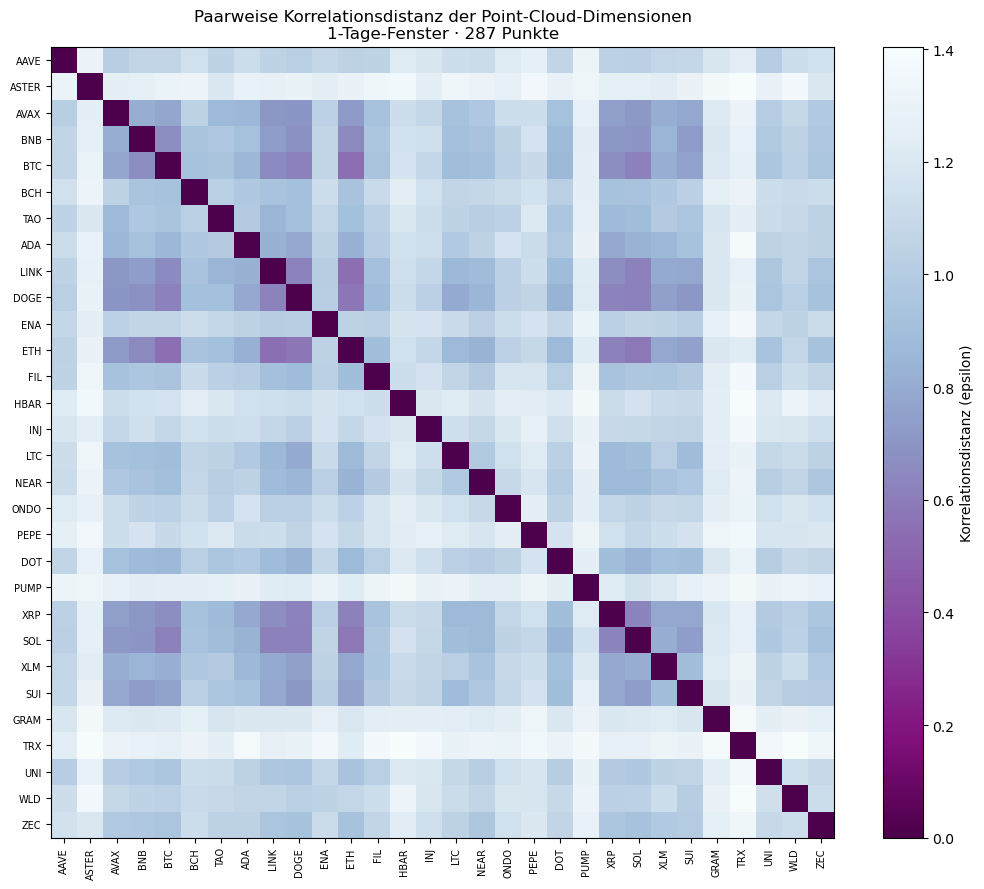

Top-10 Paare mit kleinster Distanz (staerkste Ko-Bewegung):
BTC   ETH     0.538407
LINK  ETH     0.542557
DOGE  ETH     0.573977
ETH   SOL     0.581352
BTC   DOGE    0.614720
ETH   XRP     0.616369
DOGE  SOL     0.616828
BTC   SOL     0.617912
LINK  SOL     0.617933
DOGE  XRP     0.622294
dtype: float64

Top-5 Paare mit groesster Distanz (am wenigsten verwandt):
ADA    TRX    1.378690
GRAM   TRX    1.385408
TRX    WLD    1.395362
ASTER  TRX    1.403470
HBAR   TRX    1.404179


In [13]:
# --- Visualisierung 4: Distanz-Heatmap aller Assets ---
dist_df = pd.DataFrame(dist_matrix, columns=syms, index=syms)

fig, ax = plt.subplots(figsize=(max(8, len(syms) * 0.35), max(6, len(syms) * 0.3)))
colormax=dist_df.values.max()
im = ax.imshow(dist_df.values, vmin=0, vmax=colormax, cmap="BuPu_r", aspect="auto")
plt.colorbar(im, ax=ax, label="Korrelationsdistanz (epsilon)")
ax.set_xticks(range(len(syms))); ax.set_xticklabels(syms, rotation=90, fontsize=7)
ax.set_yticks(range(len(syms))); ax.set_yticklabels(syms, fontsize=7)
ax.set_title(f"Paarweise Korrelationsdistanz der Point-Cloud-Dimensionen\n{WINDOW_DAYS}-Tage-Fenster · {result['n_points']} Punkte")
plt.tight_layout()
plt.savefig("viz4_heatmap.png", dpi=120)
plt.show()
plt.close("all")

# Kleine Distanz = aehnliches Verhalten -> aufsteigend sortieren fuer die "engsten" Paare.
pairs = (dist_df.where(np.triu(np.ones(dist_df.shape), k=1).astype(bool)).stack().sort_values(ascending=True))
print("Top-10 Paare mit kleinster Distanz (staerkste Ko-Bewegung):")
print(pairs.head(10))
print("\nTop-5 Paare mit groesster Distanz (am wenigsten verwandt):")
print(pairs.tail(5).to_string())

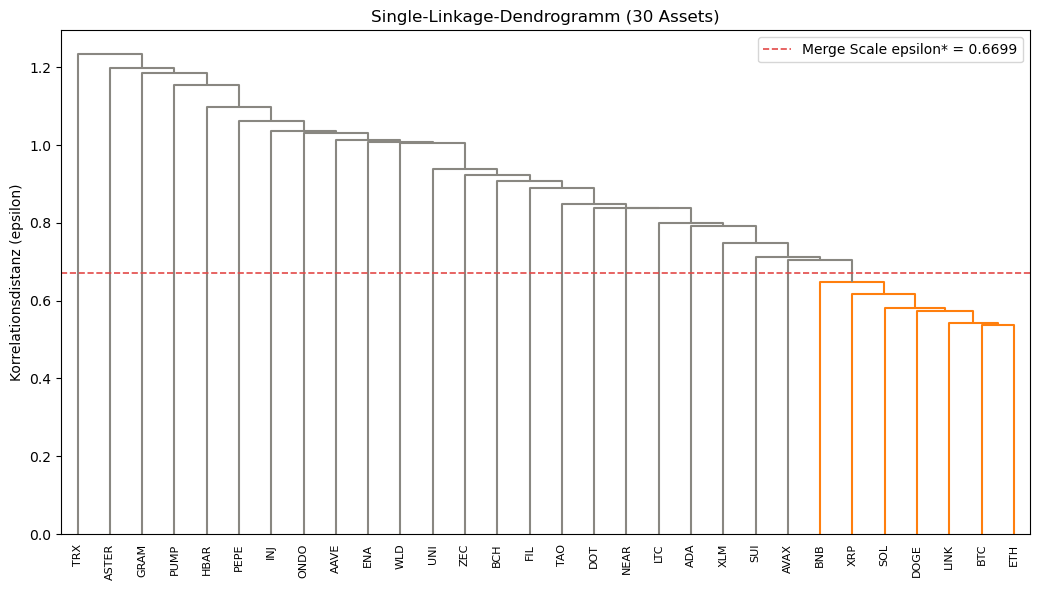

In [14]:
# --- Visualisierung 5: Dendrogramm der Assets ---
# Zeigt den Cluster-Baum: Assets, die frueh (niedrige Distanz) zusammengefuehrt
# werden, haben ein sehr aehnliches Return-Verhalten. Je hoeher der Merge-Punkt
# auf der y-Achse, desto schwaecher die Verbindung.
from cloudvisualisation import plot_dendrogram

merge_scale = 0.6699  # Beispiel-Schwelle fuer die Cluster-Einfaerbung
z_dendro = plot_dendrogram(dist_matrix, syms, color_threshold=merge_scale)

In [ ]:
# --- Visualisierung 7: Epsilon-Slider (Vietoris-Rips 1-Skelett) ---
# Assets als Knoten (MDS-Layout aus der Distanzmatrix). Kanten erscheinen, sobald
# die paarweise Korrelationsdistanz <= epsilon ist. Beim Hochziehen des Sliders sieht
# man live, wie isolierte Assets (epsilon=0) zu Cliquen verschmelzen.
from cloudvisualisation import plot_vietoris_rips_epsilon_slider

plot_vietoris_rips_epsilon_slider(dist_matrix, syms)

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='epsilon:', layout=Layout(wi…

In [16]:
# --- Visualisierung 8: H0-Persistenz-Barcode ---
# Ein Balken pro Merge-Event (birth=0 -> death=epsilon). Lange Balken mit vielen
# beteiligten Assets = strukturell stabile Cliquen (hohe Persistenz = robust gegen
# Marktvolatilitaet, siehe PDF "Another important point").
from cloudvisualisation import plot_h0_persistence_barcode

z_linkage = plot_h0_persistence_barcode(dist_matrix, syms)

print(f"\nGroesste Merge-Events")
merge_df = pd.DataFrame(z_linkage, columns=["cluster_1", "cluster_2", "death", "size"])
print(merge_df.sort_values("death", ascending=False).head(5).to_string(index=False))

Anzahl Cluster-Intervalle: 58

Groesste Merge-Events
 cluster_1  cluster_2    death  size
      26.0       57.0 1.233107  30.0
       1.0       56.0 1.197754  29.0
      25.0       55.0 1.184347  28.0
      20.0       54.0 1.153448  27.0
      13.0       53.0 1.097137  26.0


In [17]:
# --- Visualisierung 6: Interaktive 3D Point Cloud (frei wählbare Achsen) ---
# X/Y/Z-Achse per Dropdown beliebig auf ein Asset legen -> "durch" die
# n-dimensionale Wolke wandern. Farbe = Return auf der X-Achse (diverging).
from cloudvisualisation import plot_point_cloud_3d_interactive

plot_point_cloud_3d_interactive(pc, syms, timestamps=result["timestamps"])


interactive(children=(Dropdown(description='X-Achse:', options=('AAVE', 'ASTER', 'AVAX', 'BNB', 'BTC', 'BCH', …